# Pré-processamento — Victor
Base: saída final da extração. Este notebook não reexecuta a extração nem modifica os microdados. Diagnóstico descritivo usa a base completa; transformações do modelo são aprendidas apenas nos treinos. Não executa os 385 experimentos.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'data/interim/pns_base_eda.parquet').is_file():
    raise FileNotFoundError('Abra na raiz do repositório ou em notebooks; base intermediária ausente.')
sys.path.insert(0, str(ROOT))
df = pd.read_parquet(ROOT / 'data/interim/pns_base_eda.parquet')
print('Dimensões:', df.shape)
display(pd.DataFrame({'tipo': df.dtypes.astype(str), 'ausentes': df.isna().sum()}))
display(df['ativo_lazer'].value_counts(dropna=False))
assert df.shape == (88456, 11), 'Divergência com README: investigar antes de prosseguir'
assert df['ativo_lazer'].isin([0, 1]).all()
assert not df.isna().any().any(), 'Base diverge da extração documentada'


Dimensões: (88456, 11)


,tipo,ausentes
idade,int64,0
sexo,str,0
escolaridade,str,0
renda_per_capita,int64,0
uf,str,0
situacao_trabalho,str,0
area_residencia,str,0
raca_cor,str,0
estado_civil,str,0
numero_moradores,int64,0


ativo_lazer
0    63391
1    25065
Name: count, dtype: Int64

## Quartis e extremos
Q1 e Q3 delimitam os 50% centrais. IQR = Q3 − Q1. Pontos fora de Q1 − 1,5 IQR e Q3 + 1,5 IQR são sinais estatísticos, não provas de erro. Nenhuma linha é removida aqui.

,Q1,mediana,Q3,IQR,inferior,superior,extremos
idade,33.0,46.0,60.0,27.0,-7.5,100.5,18
renda_per_capita,499.0,998.0,1667.0,1168.0,-1253.0,3419.0,8397
numero_moradores,2.0,3.0,4.0,2.0,-1.0,7.0,807


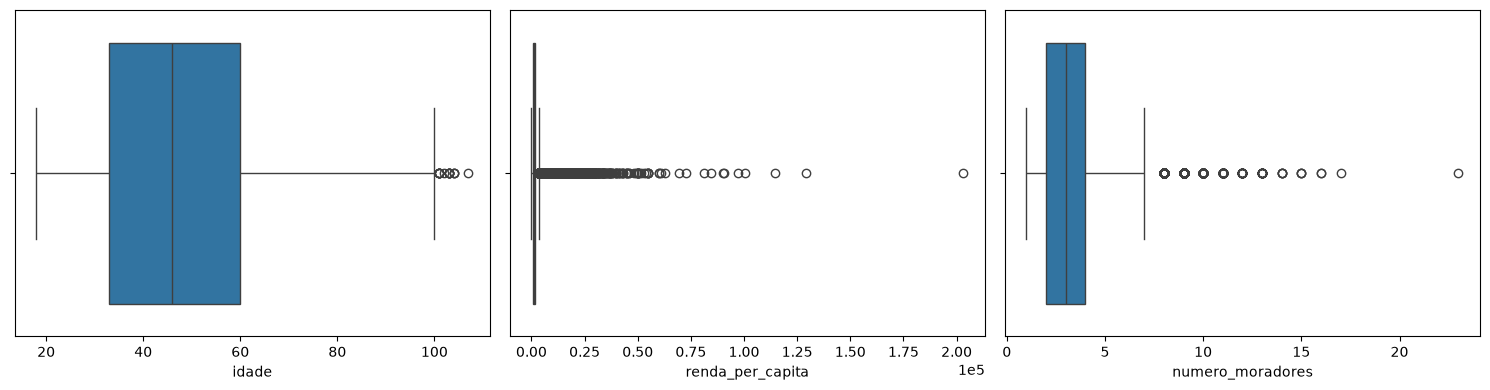

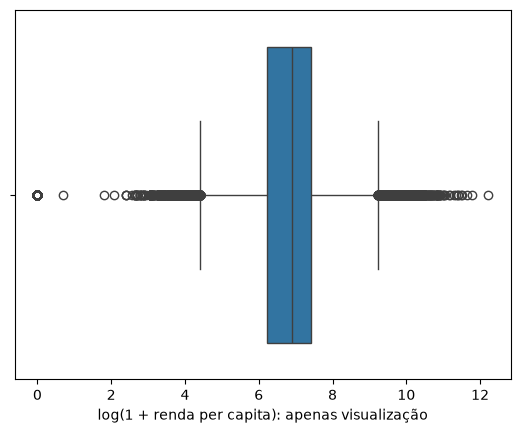

In [2]:
numericas = ['idade', 'renda_per_capita', 'numero_moradores']
q = df[numericas].quantile([.25, .5, .75]).T
q.columns = ['Q1', 'mediana', 'Q3']
q['IQR'] = q.Q3 - q.Q1
q['inferior'] = q.Q1 - 1.5*q.IQR
q['superior'] = q.Q3 + 1.5*q.IQR
q['extremos'] = [int(((df[c] < q.loc[c, 'inferior']) | (df[c] > q.loc[c, 'superior'])).sum()) for c in numericas]
display(q)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna in zip(axes, numericas):
    sns.boxplot(data=df, x=coluna, ax=ax, showfliers=True)
axes[1].ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
plt.tight_layout()
plt.show()
sns.boxplot(x=np.log1p(df['renda_per_capita']))
plt.xlabel('log(1 + renda per capita): apenas visualização')
plt.show()


A extração excluiu 48 durações maiores que seis horas/dia antes do filtro de adultos; não reaplicamos esse filtro. Os extremos socioeconômicos foram preservados: idade elevada, renda muito assimétrica e domicílios numerosos podem representar situações legítimas. O gráfico da renda original fica comprimido pela cauda superior; o log ajuda a enxergar a distribuição, sem substituir a renda original.

## Alternativas para kNN
One-hot representa cada categoria por indicadores sem impor ordem, inclusive UF e escolaridade. Min-Max usa extremos do treino; valores futuros podem sair de [0,1]. StandardScaler usa média/desvio; RobustScaler usa mediana/IQR, mas não elimina extremos. Comparar preservação, log da renda e limitação por IQR; esta última pode apagar diferenças sociais legítimas. Faixas por quantis são outra representação e substituem escala/extremos. Empates podem reduzir as faixas efetivas.

Imputação por média/mediana nas numéricas e moda nas categorias é preventiva: a base atual é completa. Nunca imputar o alvo. Seleção supervisionada de 25/40/50/60/75/90% e PCA de 80/90/95/99% de variância são opcionais e devem permanecer no pipeline. A saída densa simplifica PCA, mas exige avaliar memória na base completa.

In [3]:
from src.preprocessamento import (separar_xy, construir_pipeline,
    configuracoes_experimentais, validacao_cruzada)
from sklearn.model_selection import train_test_split
from sklearn.base import clone
X, y = separar_xy(df)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, train_size=240, test_size=60, stratify=y, random_state=42)
receitas = configuracoes_experimentais()
assert len(receitas) == 385
# Testes pequenos de todas as receitas; não calculam métricas nem fazem CV.
for receita in receitas:
    modelo = construir_pipeline(**receita)
    preparacao = modelo[:-1]
    treino = preparacao.fit_transform(X_treino, y_treino)
    validacao = preparacao.transform(X_validacao)
    assert np.isfinite(treino).all() and np.isfinite(validacao).all()
    assert np.issubdtype(validacao.dtype, np.number)
    assert treino.shape[1] == validacao.shape[1]
    assert clone(modelo).get_params()['knn__n_neighbors'] == 5
modelo = construir_pipeline()
modelo.fit(X_treino, y_treino)
assert modelo.predict(X_validacao).shape == (60,)
assert validacao_cruzada().get_n_splits() == 10
print('385 preparações verificadas em 240/60 registros reais; um kNN padrão ajustado.')


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consi

C:\Users\victor\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


385 preparações verificadas em 240/60 registros reais; um kNN padrão ajustado.


## Integração — Pedro e Rafael
Exemplo para os experimentos futuros (não executado):
```python
from sklearn.model_selection import cross_validate
X, y = separar_xy(df)
receita = configuracoes_experimentais()[0]
resultado = cross_validate(construir_pipeline(**receita), X, y,
    cv=validacao_cruzada(), scoring=['accuracy', 'f1', 'roc_auc'])
```
Não passar X já transformado para cross_validate. Verificar pelo menos dez observações por classe. As 385 combinações fixam imputação em mediana: a base completa torna mean/median equivalentes. A grade combina 11 bases, sete seleções (25/40/50/60/75/90/100%) e cinco opções de PCA (sem PCA, 80/90/95/99%). Seleção pode eliminar diferenças entre bases; limiares de PCA podem reter o mesmo subespaço. O teste externo registra grupos de matrizes e distâncias equivalentes em outputs/preprocessamento/equivalencias_configuracoes.json; não garante 385 transformações distintas nem desempenho diferente. Rafael deve registrar receitas, versões, avisos e resultados; confirmar como a disciplina conta configurações equivalentes. A seleção da melhor receita pelos mesmos folds traz otimismo: reservar teste ou avaliação externa para a estimativa final. Balanceamento fica pendente de decisão da equipe, sempre restrito ao treino. F1 usa classe positiva 1; matriz de confusão exige previsões fora da amostra.